# Práctica 1: Perceptrón multicapa.

Tu jefe pidió a RH que recolectara datos de desempeño de tus compañeros, los resultados se almacenaron en un csv. El punto critico de estos datos es la satisfacción del empleado, entonces ¿Podremos estimar la satisfacción de los empleados con los datos recabados?.

In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix
import tensorflow as tf
import numpy as np
from tensorflow.keras import layers, models


df = pd.read_csv('Extended_Employee_Performance_and_Productivity_Data.csv')
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 100000 entries, 0 to 99999
Data columns (total 20 columns):
 #   Column                       Non-Null Count   Dtype  
---  ------                       --------------   -----  
 0   Employee_ID                  100000 non-null  int64  
 1   Department                   100000 non-null  object 
 2   Gender                       100000 non-null  object 
 3   Age                          100000 non-null  int64  
 4   Job_Title                    100000 non-null  object 
 5   Hire_Date                    100000 non-null  object 
 6   Years_At_Company             100000 non-null  int64  
 7   Education_Level              100000 non-null  object 
 8   Performance_Score            100000 non-null  int64  
 9   Monthly_Salary               100000 non-null  float64
 10  Work_Hours_Per_Week          100000 non-null  int64  
 11  Projects_Handled             100000 non-null  int64  
 12  Overtime_Hours               100000 non-null  int64  
 13  

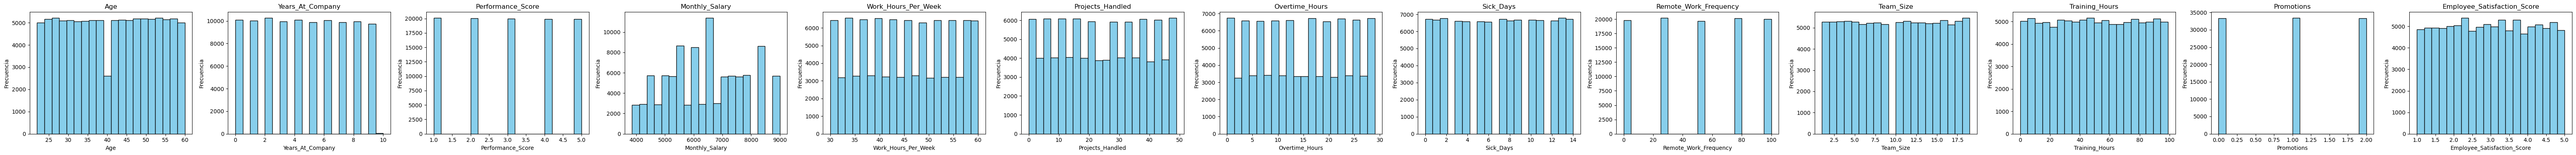

In [2]:
# Filtrar las columnas numéricas
numeric_columns = df.select_dtypes(include=['number']).drop('Employee_ID',axis=1)


# Si numeric_columns es un Index, conviértelo a lista
cols = list(numeric_columns)

fig, axes = plt.subplots(1, len(cols), figsize=(5 * len(cols), 4))

for i, col in enumerate(cols):
    axes[i].hist(df[col], bins=20, color='skyblue', edgecolor='black')
    axes[i].set_title(col)
    axes[i].set_xlabel(col)
    axes[i].set_ylabel('Frecuencia')

plt.tight_layout()
plt.show()

**Problemas**, tenemos distribuciones con picos, esos nos indica categorías. Por otro lado, tenemos variables con "valles" en su distribución (distribuciones multimodales) por lo que resultaría óptimo aplicar técnicas de feature engeneering. Por último tenemos distribuciones uniformes, por lo que cada una requeriría un procesamiento indivudual, hagamos la vista gorda e intentemos ajustar un MLP con estos datos, solo estandaricemos nuestros datos.

---

## Implementación de Red:

To**memos los datos numéricos como nuestra variable X, y la variable objetivo como ***'Employee_Satisfaction_Score'***.
- **Actividad 1**: Para todos los strings ``'@modif@'`` que aparescan en el siguiente bloque de código cámbialos para que el código funcione.

In [3]:
X = numeric_columns.drop('Employee_Satisfaction_Score', axis=1)
y = numeric_columns['Employee_Satisfaction_Score']
y = y.apply(lambda x: round(x)-1) #Cambiamos la variable objetivo a 5 categorías numéricas

scaler = StandardScaler()
X_standar = scaler.fit_transform(X)

X_train, X_test, y_train, y_test = train_test_split(X_standar, y, test_size=0.33, random_state=42, stratify=y)

y_onehot_train = tf.keras.utils.to_categorical(y_train, 5)
y_onehot_test = tf.keras.utils.to_categorical(y_test, 5)

print('Dimensiones de X:', X.shape)
print('Dimensiones de entrenamiento:', X_train.shape)
print('Dimensiones de prueba:', X_test.shape)
print('Clases y muestras:', y.value_counts().sort_index().to_dict())

Dimensiones de X: (100000, 12)
Dimensiones de entrenamiento: (67000, 12)
Dimensiones de prueba: (33000, 12)
Clases y muestras: {0: 12265, 1: 25326, 2: 24926, 3: 25311, 4: 12172}


- **Actividad 2:** Implementa 3 arquitecturas de MLP, cada una con su propio nombre, cambiando la estructura de dichas arquitecturas (capas, neuronas por capa, función de activación, etc). 

In [4]:
tf.keras.utils.set_random_seed(42)

# Arquitectura 1: red básica
mlp_basico = models.Sequential([
    layers.Input(shape=(X_train.shape[1],), name='entrada'),
    layers.Dense(64, activation='relu', name='oculta_1'),
    layers.Dense(32, activation='relu', name='oculta_2'),
    layers.Dense(5, activation='softmax', name='salida')
], name='MLP_Basico')

mlp_basico.summary()

Model: "MLP_Basico"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ oculta_1 (Dense)                │ (None, 64)             │           832 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ oculta_2 (Dense)                │ (None, 32)             │         2,080 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ salida (Dense)                  │ (None, 5)              │           165 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 3,077 (12.02 KB)

 Trainable params: 3,077 (12.02 KB)

 Non-trainable params: 0 (0.00 B)

In [5]:
tf.keras.utils.set_random_seed(42)

# Arquitectura 2: red profunda con activaciones diferentes
mlp_profundo = models.Sequential([
    layers.Input(shape=(X_train.shape[1],), name='entrada'),
    layers.Dense(128, activation='relu', name='oculta_1'),
    layers.Dense(64, activation='elu', name='oculta_2'),
    layers.Dense(32, activation='tanh', name='oculta_3'),
    layers.Dense(16, activation='relu', name='oculta_4'),
    layers.Dense(5, activation='softmax', name='salida')
], name='MLP_Profundo')

mlp_profundo.summary()

Model: "MLP_Profundo"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ oculta_1 (Dense)                │ (None, 128)            │         1,664 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ oculta_2 (Dense)                │ (None, 64)             │         8,256 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ oculta_3 (Dense)                │ (None, 32)             │         2,080 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ oculta_4 (Dense)                │ (None, 16)             │           528 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ salida (Dense)                  │ (None, 5)              │            85 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 12,613 (49.27 KB)

 Trainable params: 12,613 (49.27 KB)

 Non-trainable params: 0 (0.00 B)

In [6]:
tf.keras.utils.set_random_seed(42)

# Arquitectura 3: regularización mediante normalización y dropout
mlp_regularizado = models.Sequential([
    layers.Input(shape=(X_train.shape[1],), name='entrada'),
    layers.Dense(128, activation='relu', kernel_regularizer=tf.keras.regularizers.l2(0.001), name='oculta_1'),
    layers.BatchNormalization(name='normalizacion_1'),
    layers.Dropout(0.30, name='dropout_1'),
    layers.Dense(64, activation='selu', kernel_regularizer=tf.keras.regularizers.l2(0.001), name='oculta_2'),
    layers.BatchNormalization(name='normalizacion_2'),
    layers.Dropout(0.20, name='dropout_2'),
    layers.Dense(32, activation='relu', name='oculta_3'),
    layers.Dense(5, activation='softmax', name='salida')
], name='MLP_Regularizado')

mlp_regularizado.summary()

Model: "MLP_Regularizado"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ oculta_1 (Dense)                │ (None, 128)            │         1,664 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ normalizacion_1                 │ (None, 128)            │           512 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ oculta_2 (Dense)                │ (None, 64)             │         8,256 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ normalizacion_2                 │ (None, 64)             │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_2 (Dropout)             │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ oculta_3 (Dense)                │ (None, 32)             │         2,080 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ salida (Dense)                  │ (None, 5)              │           165 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 12,933 (50.52 KB)

 Trainable params: 12,549 (49.02 KB)

 Non-trainable params: 384 (1.50 KB)

- **Actividad 3:** Compila y ajusta tus tres modelos con sus respectivos hiperparámetros.

In [7]:
modelos = {
    'MLP_Basico': (mlp_basico, tf.keras.optimizers.Adam(learning_rate=0.001)),
    'MLP_Profundo': (mlp_profundo, tf.keras.optimizers.Adam(learning_rate=0.0005)),
    'MLP_Regularizado': (mlp_regularizado, tf.keras.optimizers.RMSprop(learning_rate=0.0005))
}

historiales = {}
early_stopping = tf.keras.callbacks.EarlyStopping(
    monitor='val_accuracy', mode='max', patience=3, restore_best_weights=True
)

for nombre, (modelo, optimizador) in modelos.items():
    print(f'\nEntrenando {nombre}...')
    modelo.compile(
        optimizer=optimizador,
        loss='categorical_crossentropy',
        metrics=['accuracy']
    )
    historiales[nombre] = modelo.fit(
        X_train,
        y_onehot_train,
        validation_split=0.15,
        epochs=15,
        batch_size=128,
        callbacks=[early_stopping],
        verbose=1
    )


Entrenando MLP_Basico...


Epoch 1/15



  1/445 ━━━━━━━━━━━━━━━━━━━━ 5:05 688ms/step - accuracy: 0.1641 - loss: 1.7611


 31/445 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - accuracy: 0.2356 - loss: 1.6197    


 62/445 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - accuracy: 0.2407 - loss: 1.5974


 91/445 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - accuracy: 0.2436 - loss: 1.5877

... (467 outputs left out)


390/445 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - accuracy: 0.2628 - loss: 1.5672


409/445 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - accuracy: 0.2628 - loss: 1.5671


429/445 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - accuracy: 0.2632 - loss: 1.5670


445/445 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - accuracy: 0.2632 - loss: 1.5669 - val_accuracy: 0.2531 - val_loss: 1.5710


,Modelo,Exactitud,Pérdida
0,MLP_Basico,0.255061,1.559913
1,MLP_Profundo,0.253485,1.558358
2,MLP_Regularizado,0.253061,1.576283


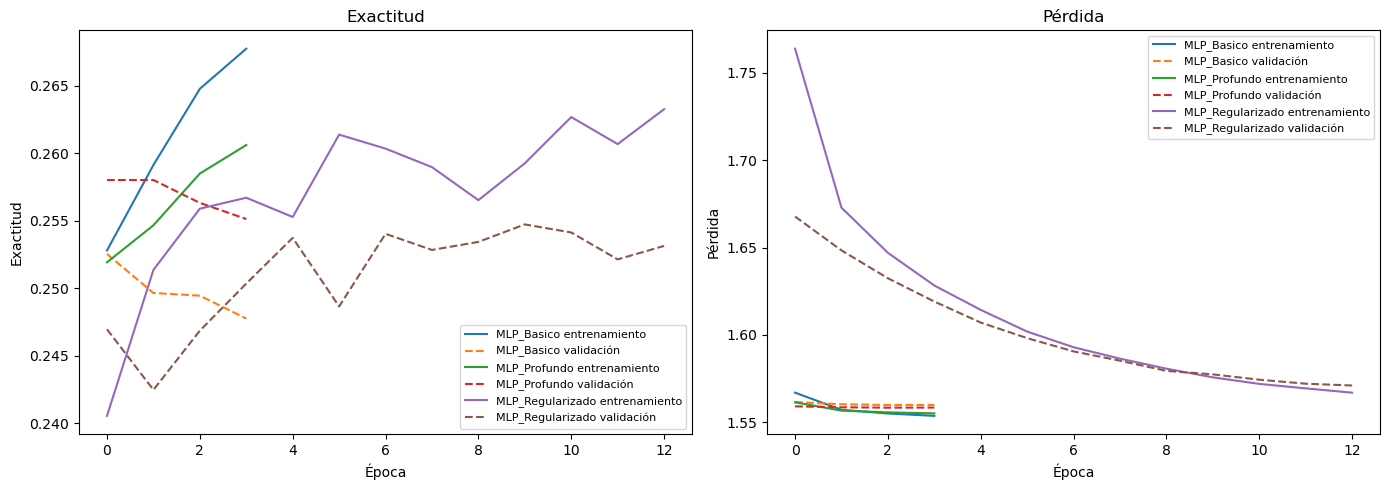

Mejor modelo en el conjunto de prueba: MLP_Basico
Reporte de clasificación:
              precision    recall  f1-score   support

           0     0.0000    0.0000    0.0000      4047
           1     0.2558    0.3331    0.2894      8358
           2     0.2539    0.2667    0.2602      8225
           3     0.2552    0.4117    0.3151      8353
           4     0.0000    0.0000    0.0000      4017

    accuracy                         0.2551     33000
   macro avg     0.1530    0.2023    0.1729     33000
weighted avg     0.1927    0.2551    0.2179     33000



C:\Users\Roxana Velasco\anaconda3\Lib\site-packages\sklearn\metrics\_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
C:\Users\Roxana Velasco\anaconda3\Lib\site-packages\sklearn\metrics\_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
C:\Users\Roxana Velasco\anaconda3\Lib\site-packages\sklearn\metrics\_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))


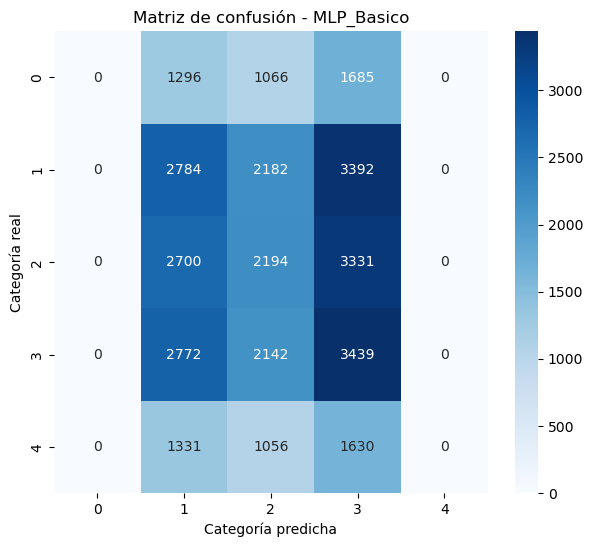

In [8]:
resultados = []

for nombre, (modelo, _) in modelos.items():
    perdida, exactitud = modelo.evaluate(X_test, y_onehot_test, verbose=0)
    resultados.append({'Modelo': nombre, 'Exactitud': exactitud, 'Pérdida': perdida})

df_resultados = pd.DataFrame(resultados).sort_values('Exactitud', ascending=False)
display(df_resultados)

fig, axes = plt.subplots(1, 2, figsize=(14, 5))
for nombre, historial in historiales.items():
    axes[0].plot(historial.history['accuracy'], label=f'{nombre} entrenamiento')
    axes[0].plot(historial.history['val_accuracy'], '--', label=f'{nombre} validación')
    axes[1].plot(historial.history['loss'], label=f'{nombre} entrenamiento')
    axes[1].plot(historial.history['val_loss'], '--', label=f'{nombre} validación')

axes[0].set(title='Exactitud', xlabel='Época', ylabel='Exactitud')
axes[1].set(title='Pérdida', xlabel='Época', ylabel='Pérdida')
axes[0].legend(fontsize=8)
axes[1].legend(fontsize=8)
plt.tight_layout()
plt.show()

mejor_nombre = df_resultados.iloc[0]['Modelo']
mejor_modelo = modelos[mejor_nombre][0]
y_pred = np.argmax(mejor_modelo.predict(X_test, verbose=0), axis=1)

print(f'Mejor modelo en el conjunto de prueba: {mejor_nombre}')
print('Reporte de clasificación:')
print(classification_report(y_test, y_pred, digits=4))

plt.figure(figsize=(7, 6))
sns.heatmap(confusion_matrix(y_test, y_pred), annot=True, fmt='d', cmap='Blues')
plt.xlabel('Categoría predicha')
plt.ylabel('Categoría real')
plt.title(f'Matriz de confusión - {mejor_nombre}')
plt.show()

- **Actividad 4:** Sube tus cambios al repositorio, envía el link de tu repositorio a la actividad 2 de tu checkpoint 2 y contesta las preguntas de dicha actividad.